In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("data/crop_production.csv")

In [5]:
df

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0
...,...,...,...,...,...,...,...
246086,West Bengal,PURULIA,2014,Summer,Rice,306.0,801.0
246087,West Bengal,PURULIA,2014,Summer,Sesamum,627.0,463.0
246088,West Bengal,PURULIA,2014,Whole Year,Sugarcane,324.0,16250.0
246089,West Bengal,PURULIA,2014,Winter,Rice,279151.0,597899.0


In [6]:
df.shape

(246091, 7)

In [7]:
df.head()

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


In [8]:
df.columns.tolist()

['State_Name',
 'District_Name',
 'Crop_Year',
 'Season',
 'Crop',
 'Area',
 'Production']

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  str    
 1   District_Name  246091 non-null  str    
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  str    
 4   Crop           246091 non-null  str    
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 22.0 MB


In [10]:
df.isnull().sum()

State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

data quality

In [12]:
print(df.describe())

           Crop_Year          Area    Production
count  246091.000000  2.460910e+05  2.423610e+05
mean     2005.643018  1.200282e+04  5.825034e+05
std         4.952164  5.052340e+04  1.706581e+07
min      1997.000000  4.000000e-02  0.000000e+00
25%      2002.000000  8.000000e+01  8.800000e+01
50%      2006.000000  5.820000e+02  7.290000e+02
75%      2010.000000  4.392000e+03  7.023000e+03
max      2015.000000  8.580100e+06  1.250800e+09


In [13]:
print(df.describe(include="object"))

           State_Name District_Name       Season    Crop
count          246091        246091       246091  246091
unique             33           646            6     124
top     Uttar Pradesh       BIJAPUR  Kharif         Rice
freq            33306           945        95951   15104


C:\Users\akber\AppData\Local\Temp\ipykernel_23628\1129007761.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include="object"))


In [14]:
print(df.isnull().sum())

State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
#investigating missing values

missing_data = pd.DataFrame({
    "Missing_Count" : df.isnull().sum(),
    "Missing_Percentage" : df.isnull().mean().mul(100).round(2)
})

In [17]:
missing_data = missing_data.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print(missing_data)

               Missing_Count  Missing_Percentage
Production              3730                1.52
District_Name              0                0.00
State_Name                 0                0.00
Crop_Year                  0                0.00
Season                     0                0.00
Crop                       0                0.00
Area                       0                0.00


In [18]:
#checking invalid values

print("Negative_Area_Values:", (df["Area"] < 0).sum())

Negative_Area_Values: 0


In [19]:
print("Negative_Production_Values:", (df["Production"] < 0).sum())

Negative_Production_Values: 0


In [20]:
print("Zero_Area_Values:", (df["Area"] == 0).sum())

Zero_Area_Values: 0


In [21]:
print("Zero_Production_Values:", (df["Production"] == 0).sum())

Zero_Production_Values: 3523


In [22]:
#checking the year range:

print("First Year:", (df["Crop_Year"].min()))
print("Last Year:", (df["Crop_Year"].max()))

First Year: 1997
Last Year: 2015


In [23]:
print("\n Records per Year: ")
print(df["Crop_Year"].value_counts().sort_index())


 Records per Year: 
Crop_Year
1997     8899
1998    11533
1999    12515
2000    13658
2001    13361
2002    16671
2003    17287
2004    14117
2005    13799
2006    14328
2007    14526
2008    14550
2009    14116
2010    14065
2011    14071
2012    13410
2013    13650
2014    10973
2015      562
Name: count, dtype: int64


In [24]:
missing_production = df[df["Production"].isna()]
print("Missing Production Records: ", len(missing_production))
missing_production.head(10)


Missing Production Records:  3730


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
46,Andaman and Nicobar Islands,NICOBARS,2005,Whole Year,Arecanut,795.67,NaN
51,Andaman and Nicobar Islands,NICOBARS,2005,Whole Year,Dry chillies,17.00,NaN
623,Andhra Pradesh,ANANTAPUR,2007,Kharif,Moong(Green Gram),1000.00,NaN
630,Andhra Pradesh,ANANTAPUR,2007,Rabi,Horse-gram,1000.00,NaN
698,Andhra Pradesh,ANANTAPUR,2009,Rabi,Rapeseed &Mustard,8.00,NaN
723,Andhra Pradesh,ANANTAPUR,2010,Kharif,Other Kharif pulses,1.00,NaN
1153,Andhra Pradesh,CHITTOOR,2001,Rabi,Wheat,4.00,NaN
1317,Andhra Pradesh,CHITTOOR,2004,Rabi,Wheat,2.00,NaN
1419,Andhra Pradesh,CHITTOOR,2007,Kharif,Moong(Green Gram),1000.00,NaN
1423,Andhra Pradesh,CHITTOOR,2007,Kharif,Small millets,1000.00,NaN


In [25]:
df['Production'].isnull().sum()

np.int64(3730)

In [26]:
missing_by_state = (missing_production.groupby('State_Name').size().sort_values(ascending=False))
print(missing_by_state.head(10))

State_Name
Haryana           1335
Rajasthan          448
Chhattisgarh       341
Madhya Pradesh     339
Tamil Nadu         281
Kerala             258
Maharashtra        132
Uttar Pradesh      117
Gujarat             71
Uttarakhand         71
dtype: int64


In [27]:
missing_by_crop = (missing_production.groupby('Crop').size().sort_values(ascending=False))
print(missing_by_crop.head(10))

Crop
Sesamum                225
Moong(Green Gram)      212
Sannhamp               212
Maize                  160
Urad                   140
Cotton(lint)           136
Gram                   134
Other Kharif pulses    110
Castor seed            106
Arhar/Tur              102
dtype: int64


In [28]:
zero_production = df[df['Production'] == 0]
print("Zero Production Records: ", len(zero_production))
zero_production.head(10)

Zero Production Records:  3523


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
397,Andhra Pradesh,ANANTAPUR,2002,Kharif,Soyabean,51.0,0.0
424,Andhra Pradesh,ANANTAPUR,2002,Whole Year,Cucumber,18.0,0.0
428,Andhra Pradesh,ANANTAPUR,2002,Whole Year,other fibres,132.0,0.0
430,Andhra Pradesh,ANANTAPUR,2002,Whole Year,Other Vegetables,1767.0,0.0
481,Andhra Pradesh,ANANTAPUR,2003,Whole Year,Cucumber,51.0,0.0
486,Andhra Pradesh,ANANTAPUR,2003,Whole Year,Other Vegetables,1783.0,0.0
1203,Andhra Pradesh,CHITTOOR,2002,Whole Year,Cabbage,4.0,0.0
1208,Andhra Pradesh,CHITTOOR,2002,Whole Year,Cucumber,8.0,0.0
1213,Andhra Pradesh,CHITTOOR,2002,Whole Year,Other Vegetables,918.0,0.0
1215,Andhra Pradesh,CHITTOOR,2002,Whole Year,Peas (vegetable),1.0,0.0


In [29]:
zero_production.tail(10)

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
212429,Uttar Pradesh,GONDA,2003,Kharif,Moong(Green Gram),1.0,0.0
212430,Uttar Pradesh,GONDA,2003,Kharif,Moth,1.0,0.0
212911,Uttar Pradesh,GORAKHPUR,2003,Kharif,Moong(Green Gram),2.0,0.0
219474,Uttar Pradesh,LALITPUR,2003,Kharif,Bajra,1.0,0.0
220878,Uttar Pradesh,MAHOBA,2002,Kharif,Bajra,1.0,0.0
221362,Uttar Pradesh,MAINPURI,2003,Rabi,Linseed,1.0,0.0
222672,Uttar Pradesh,MEERUT,2002,Kharif,Moong(Green Gram),1.0,0.0
224493,Uttar Pradesh,PILIBHIT,2002,Kharif,Moong(Green Gram),1.0,0.0
227377,Uttar Pradesh,SANT RAVIDAS NAGAR,2003,Rabi,Linseed,1.0,0.0
231266,Uttar Pradesh,VARANASI,2003,Kharif,Moth,1.0,0.0


In [30]:
#invetsigating why there are less records in the year 2015

year_summary = (
    df.groupby("Crop_Year")
    .agg(
        Total_Records=("Crop", "size"),
        Unique_States=("State_Name", "nunique"),
        Unique_Districts=("District_Name", "nunique"),
        Unique_Crops=("Crop", "nunique"),
        Missing_Production=("Production", lambda x: x.isna().sum())
    )
)

print(year_summary)

           Total_Records  Unique_States  Unique_Districts  Unique_Crops  \
Crop_Year                                                                 
1997                8899             23               473            57   
1998               11533             27               495            59   
1999               12515             28               514            59   
2000               13658             31               543            61   
2001               13361             31               542            61   
2002               16671             32               565           106   
2003               17287             32               580           103   
2004               14117             33               585            53   
2005               13799             33               590            53   
2006               14328             32               579            53   
2007               14526             32               602            54   
2008               14550 

In [31]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [32]:
df_raw = df.copy()

In [33]:
df_clean = df.copy()

In [34]:
text_columns = df_clean.select_dtypes(include="object").columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("Original dataset shape: ", df_raw.shape)
print("Working dataset shape: ",df_clean.shape)

Original dataset shape:  (246091, 7)
Working dataset shape:  (246091, 7)


C:\Users\akber\AppData\Local\Temp\ipykernel_23628\3514346571.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include="object").columns


In [35]:
print("Unique seasons:")
print(sorted(df_clean["Season"].dropna().unique()))

print("\nUnique states:", df_clean["State_Name"].nunique())
print("Unique districts:", df_clean["District_Name"].nunique())
print("Unique crops:", df_clean["Crop"].nunique())

print("\nMissing production values:", df_clean["Production"].isna().sum())

Unique seasons:
['Autumn', 'Kharif', 'Rabi', 'Summer', 'Whole Year', 'Winter']

Unique states: 33
Unique districts: 646
Unique crops: 124

Missing production values: 3730


In [36]:
df_clean["Production_Missing"] = df_clean["Production"].isna()

print(
    df_clean["Production_Missing"]
    .value_counts()
)

Production_Missing
False    242361
True       3730
Name: count, dtype: int64


In [37]:
year_coverage = (
    df_clean.groupby("Crop_Year")
    .agg(
        Records=("Crop", "size"),
        States=("State_Name", "nunique"),
        Districts=("District_Name", "nunique"),
        Crops=("Crop", "nunique")
    )
    .reset_index()
)

print(year_coverage.tail(5).to_string(index=False))

 Crop_Year  Records  States  Districts  Crops
      2011    14071      25        521     62
      2012    13410      24        517     71
      2013    13650      24        506     78
      2014    10973      22        427     76
      2015      562       2         34     17


In [38]:
state_production = (
    df_clean.dropna(subset=["Production"])
    .groupby("State_Name", as_index=False)
    .agg(
        Total_Production=("Production", "sum"),
        Crop_Records=("Production", "count"),
        Total_Area=("Area", "sum")
    )
    .sort_values("Total_Production", ascending=False)
)

print(state_production.head(10))

                     State_Name  Total_Production  Crop_Records    Total_Area
15                       Kerala      9.788005e+10          4003  3.180225e+07
1                Andhra Pradesh      1.732459e+10          9561  1.315073e+08
27                   Tamil Nadu      1.207644e+10         13266  9.541695e+07
30                Uttar Pradesh      3.234493e+09         33189  4.336223e+08
3                         Assam      2.111752e+09         14622  7.037875e+07
32                  West Bengal      1.397904e+09          9597  2.154030e+08
17                  Maharashtra      1.263641e+09         12496  3.221860e+08
14                    Karnataka      8.634298e+08         21079  2.029086e+08
0   Andaman and Nicobar Islands      7.182232e+08           201  3.370834e+05
24                       Punjab      5.863850e+08          3143  1.267152e+08


In [39]:
df_analysis = df_clean[df_clean["Crop_Year"] <= 2014].copy()

# Calculate total reported production by state
state_production = (
    df_analysis.dropna(subset=["Production"])
    .groupby("State_Name", as_index=False)
    .agg(
        Total_Production=("Production", "sum"),
        Production_Records=("Production", "count")
    )
    .sort_values("Total_Production", ascending=False)
)

# Display the top 10 states
top_10_states = state_production.head(10)

print(top_10_states.to_string(index=False))

                 State_Name  Total_Production  Production_Records
                     Kerala      9.788005e+10                4003
             Andhra Pradesh      1.732459e+10                9561
                 Tamil Nadu      1.207644e+10               13266
              Uttar Pradesh      3.234493e+09               33189
                      Assam      2.111752e+09               14622
                West Bengal      1.397904e+09                9597
                Maharashtra      1.263641e+09               12496
                  Karnataka      8.634298e+08               21079
Andaman and Nicobar Islands      7.182232e+08                 201
                     Punjab      5.863850e+08                3143


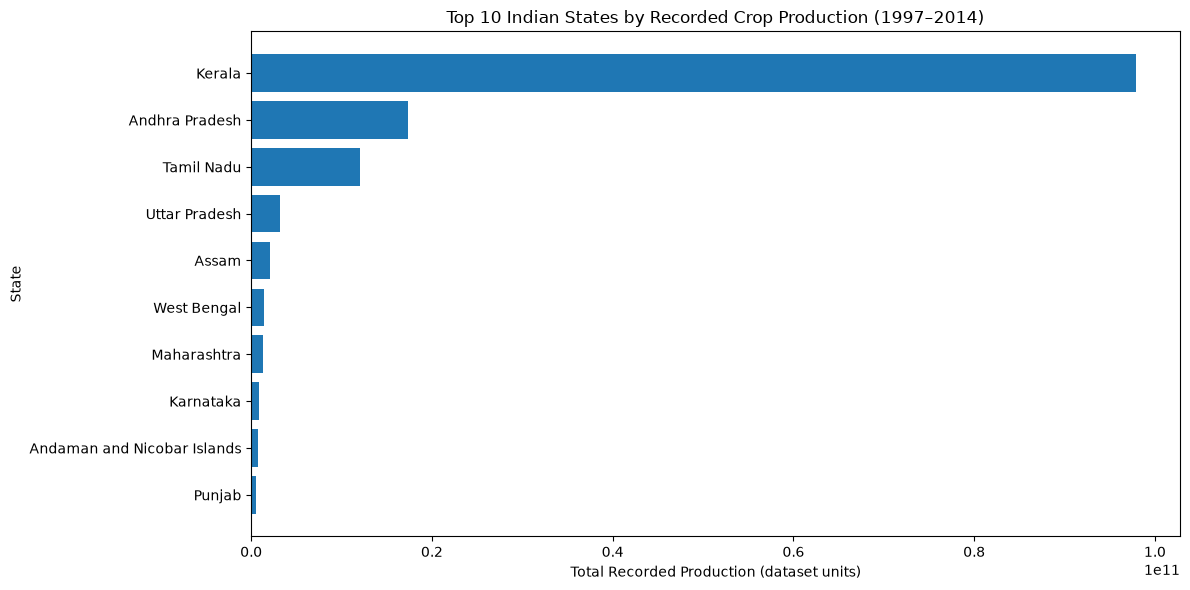

In [40]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_states["State_Name"],
    top_10_states["Total_Production"]
)

plt.xlabel("Total Recorded Production (dataset units)")
plt.ylabel("State")
plt.title("Top 10 Indian States by Recorded Crop Production (1997–2014)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
# Calculate yield only where production and area are available
df_yield = df_analysis.dropna(
    subset=["Production", "Area"]
).copy()

df_yield["Yield_Per_Hectare"] = (
    df_yield["Production"] / df_yield["Area"]
)

print(
    df_yield[
        ["State_Name", "Crop", "Area", "Production", "Yield_Per_Hectare"]
    ].head(10)
)

                    State_Name                 Crop     Area  Production  \
0  Andaman and Nicobar Islands             Arecanut   1254.0      2000.0   
1  Andaman and Nicobar Islands  Other Kharif pulses      2.0         1.0   
2  Andaman and Nicobar Islands                 Rice    102.0       321.0   
3  Andaman and Nicobar Islands               Banana    176.0       641.0   
4  Andaman and Nicobar Islands            Cashewnut    720.0       165.0   
5  Andaman and Nicobar Islands              Coconut  18168.0  65100000.0   
6  Andaman and Nicobar Islands           Dry ginger     36.0       100.0   
7  Andaman and Nicobar Islands            Sugarcane      1.0         2.0   
8  Andaman and Nicobar Islands         Sweet potato      5.0        15.0   
9  Andaman and Nicobar Islands              Tapioca     40.0       169.0   

   Yield_Per_Hectare  
0           1.594896  
1           0.500000  
2           3.147059  
3           3.642045  
4           0.229167  
5        3583.223250  
6 

In [42]:
crop_yield = (
    df_analysis.dropna(subset=["Production", "Area"])
    .groupby("Crop")
    .agg(
        Total_Production=("Production", "sum"),
        Total_Area=("Area", "sum")
    )
)

crop_yield["Yield_Per_Hectare"] = (
    crop_yield["Total_Production"] / crop_yield["Total_Area"]
)

crop_yield = crop_yield.sort_values(
    "Yield_Per_Hectare", ascending=False
)

print(crop_yield.head(15))

             Total_Production   Total_Area  Yield_Per_Hectare
Crop                                                         
Coconut          1.299816e+11  28336669.32        4587.046831
Sugarcane        5.535104e+09  76647260.75          72.215293
Tapioca          1.050072e+08   3517525.47          29.852579
Papaya           3.922521e+06    133044.00          29.482885
Banana           1.461327e+08   5244768.43          27.862561
Grapes           1.751593e+06     66903.00          26.181083
Potato           4.247691e+08  22227157.67          19.110366
Cabbage          3.114190e+05     20329.00          15.318953
Pineapple        2.127594e+06    162760.00          13.071971
Jute             1.815556e+08  14725338.00          12.329466
Onion            7.245305e+07   6305181.97          11.491032
Orange           2.338803e+06    205201.00          11.397620
Pome Granet      6.633400e+04      6183.00          10.728449
Tomato           4.724984e+06    444807.00          10.622549
Sapota  

In [43]:
kerala_crops = (
    df_analysis[df_analysis["State_Name"] == "Kerala"]
    .dropna(subset=["Production"])
    .groupby("Crop", as_index=False)
    .agg(
        Total_Production=("Production", "sum"),
        Records=("Production", "count")
    )
    .sort_values("Total_Production", ascending=False)
)

print(kerala_crops.head(15).to_string(index=False))

        Crop  Total_Production  Records
     Coconut      9.780304e+10      252
     Tapioca      4.611366e+07      252
        Rice      1.059335e+07      694
      Banana      7.655662e+06      238
   Sugarcane      3.819916e+06      170
    Arecanut      1.893642e+06      252
       Mango      1.650151e+06       57
      Rubber      1.175267e+06       28
Black pepper      9.715301e+05      252
   Cashewnut      9.483952e+05      252
  Dry ginger      6.010938e+05      238
      Papaya      2.676750e+05       43
   Pineapple      2.633810e+05       43
    Cardamom      1.363420e+05      105
      Coffee      1.300120e+05        6


In [44]:
coconut = df_analysis[df_analysis["Crop"] == "Coconut"]

print("Coconut production statistics:")
print(coconut["Production"].describe())

print("\nTop 10 states by coconut production:")

print(
    coconut.groupby("State_Name")["Production"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Coconut production statistics:
count    1.958000e+03
mean     6.638490e+07
std      1.779915e+08
min      0.000000e+00
25%      1.046310e+04
50%      2.391565e+05
75%      1.169568e+07
max      1.250800e+09
Name: Production, dtype: float64

Top 10 states by coconut production:
State_Name
Kerala                         9.780304e+10
Andhra Pradesh                 1.680600e+10
Tamil Nadu                     1.093774e+10
Assam                          1.954408e+09
West Bengal                    7.178412e+08
Andaman and Nicobar Islands    7.177900e+08
Goa                            5.031126e+08
Puducherry                     3.791390e+08
Telangana                      1.056730e+08
Karnataka                      5.676710e+07
Name: Production, dtype: float64


In [45]:
df_without_coconut = df_analysis[
    df_analysis["Crop"] != "Coconut"
]

state_production_no_coconut = (
    df_without_coconut
    .dropna(subset=["Production"])
    .groupby("State_Name")["Production"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 states excluding Coconut:")
print(state_production_no_coconut.head(10))

Top 10 states excluding Coconut:
State_Name
Uttar Pradesh     3.234493e+09
Maharashtra       1.263641e+09
Tamil Nadu        1.138700e+09
Karnataka         8.066627e+08
West Bengal       6.800632e+08
Punjab            5.863850e+08
Gujarat           5.242913e+08
Andhra Pradesh    5.185880e+08
Madhya Pradesh    4.488407e+08
Haryana           3.812739e+08
Name: Production, dtype: float64


In [46]:
# Filter Rice records from 1997–2014
rice_data = df_analysis[
    df_analysis["Crop"] == "Rice"
].copy()

# Calculate total rice production by state
rice_state = (
    rice_data.dropna(subset=["Production"])
    .groupby("State_Name", as_index=False)
    .agg(
        Total_Production=("Production", "sum"),
        Total_Area=("Area", "sum")
    )
    .sort_values("Total_Production", ascending=False)
)

print(rice_state.head(10).to_string(index=False))

    State_Name  Total_Production  Total_Area
   West Bengal       258092849.0 101993454.0
 Uttar Pradesh       218793359.0 103380331.0
        Punjab       179702000.0  48099000.0
Andhra Pradesh       143742455.0  46548311.0
        Odisha       113548742.0  81736043.0
    Tamil Nadu       100122666.0  32351269.0
         Bihar        92022922.0  57733396.0
  Chhattisgarh        81498618.0  58259645.0
         Assam        71801090.0  44751469.0
     Telangana        69195676.0  23842311.0


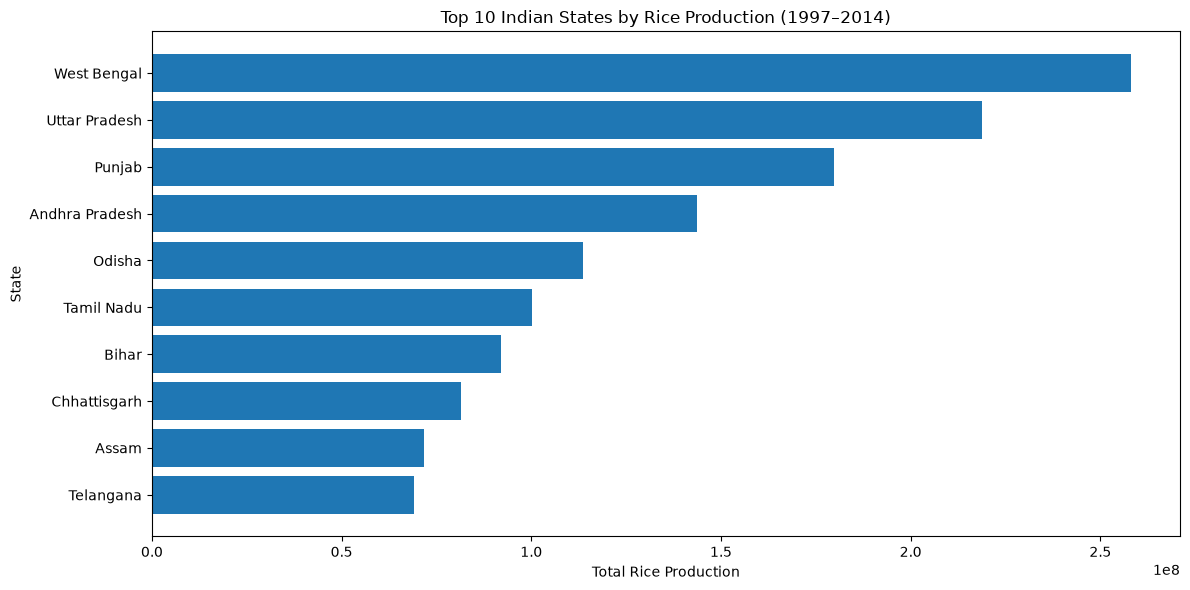

In [47]:
plt.figure(figsize=(12, 6))

plt.barh(
    rice_state.head(10)["State_Name"],
    rice_state.head(10)["Total_Production"]
)

plt.xlabel("Total Rice Production")
plt.ylabel("State")
plt.title("Top 10 Indian States by Rice Production (1997–2014)")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [48]:
# Filter Rice records
rice_data = df_analysis[
    df_analysis["Crop"] == "Rice"
].copy()

# Calculate production by season
season_production = (
    rice_data.dropna(subset=["Production"])
    .groupby("Season", as_index=False)
    .agg(
        Total_Production=("Production", "sum"),
        Total_Area=("Area", "sum"),
        Records=("Production", "count")
    )
    .sort_values("Total_Production", ascending=False)
)

print(season_production.to_string(index=False))

    Season  Total_Production   Total_Area  Records
    Kharif      941636901.85 420066548.93     6860
    Winter      376867485.45 199768194.93     2224
    Summer      126920773.53  51856565.64     2930
      Rabi       84121333.00  23943732.00      796
    Autumn       51463755.54  39427069.80     2065
Whole Year       18566447.00   7304836.00      128


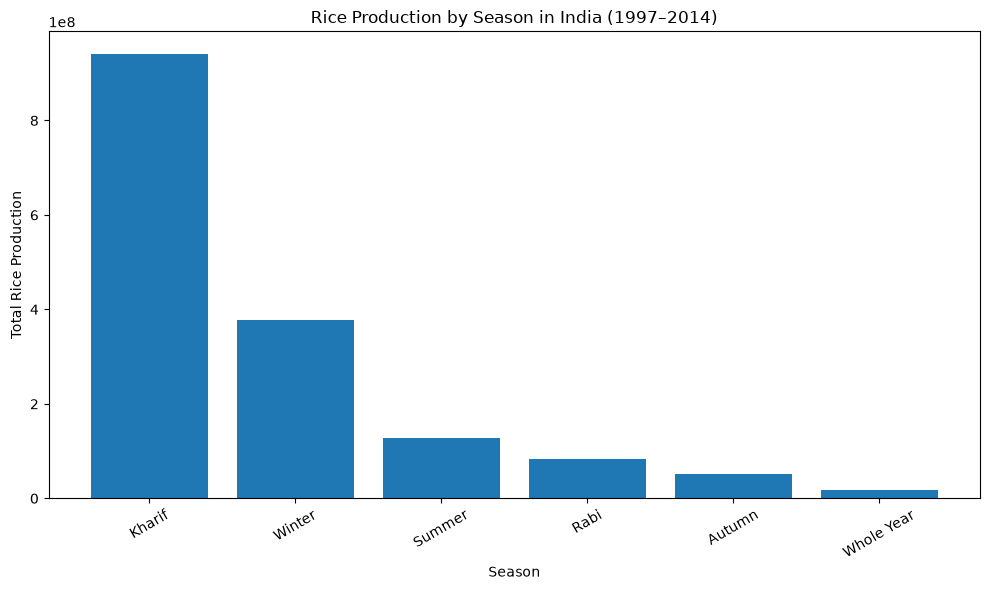

In [49]:
plt.figure(figsize=(10, 6))

plt.bar(
    season_production["Season"],
    season_production["Total_Production"]
)

plt.xlabel("Season")
plt.ylabel("Total Rice Production")
plt.title("Rice Production by Season in India (1997–2014)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [50]:
# Calculate yearly Rice production
rice_yearly = (
    rice_data.dropna(subset=["Production"])
    .groupby("Crop_Year", as_index=False)
    .agg(
        Total_Production=("Production", "sum"),
        Total_Area=("Area", "sum")
    )
    .sort_values("Crop_Year")
)

print(rice_yearly.to_string(index=False))

 Crop_Year  Total_Production  Total_Area
      1997       65848504.00 30706467.00
      1998       78761219.00 38716952.00
      1999       77917065.60 37058642.00
      2000       83092698.80 43190617.00
      2001       90057868.00 42745829.00
      2002       71453399.67 40795160.29
      2003       87835972.97 43164001.06
      2004       84172521.28 42664665.23
      2005       89587185.75 43519563.58
      2006       91676287.34 43183913.59
      2007       92064810.00 42026145.31
      2008       95261272.07 43562353.00
      2009       87356341.31 40582664.00
      2010       95176207.10 41765865.50
      2011      102093897.48 42011854.74
      2012      100330481.00 47098615.00
      2013      102872769.00 40485866.00
      2014      104018196.00 39087773.00


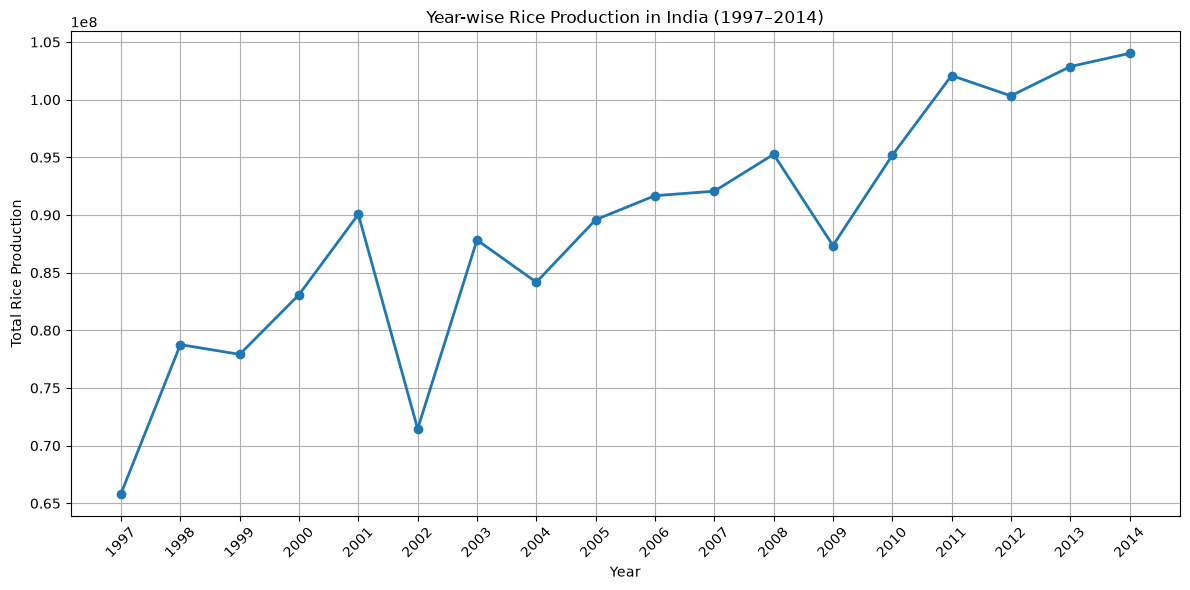

In [51]:
plt.figure(figsize=(12, 6))

plt.plot(
    rice_yearly["Crop_Year"],
    rice_yearly["Total_Production"],
    marker="o",
    linewidth=2
)

plt.xlabel("Year")
plt.ylabel("Total Rice Production")
plt.title("Year-wise Rice Production in India (1997–2014)")

plt.xticks(rice_yearly["Crop_Year"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [52]:
# Calculate yearly yield
rice_yearly["Yield_Per_Hectare"] = (
    rice_yearly["Total_Production"] /
    rice_yearly["Total_Area"]
)

print(
    rice_yearly[
        ["Crop_Year", "Yield_Per_Hectare"]
    ].to_string(index=False)
)

 Crop_Year  Yield_Per_Hectare
      1997           2.144451
      1998           2.034283
      1999           2.102534
      2000           1.923860
      2001           2.106822
      2002           1.751517
      2003           2.034936
      2004           1.972886
      2005           2.058550
      2006           2.122927
      2007           2.190656
      2008           2.186780
      2009           2.152553
      2010           2.278804
      2011           2.430121
      2012           2.130221
      2013           2.540955
      2014           2.661144


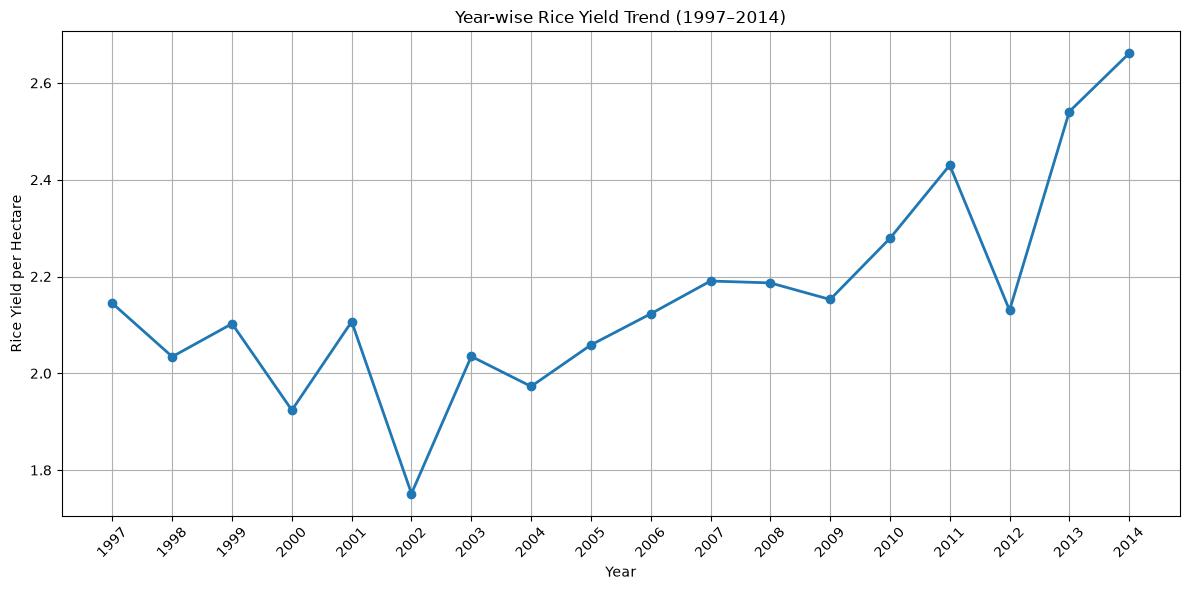

In [53]:
plt.figure(figsize=(12, 6))

plt.plot(
    rice_yearly["Crop_Year"],
    rice_yearly["Yield_Per_Hectare"],
    marker="o",
    linewidth=2
)

plt.xlabel("Year")
plt.ylabel("Rice Yield per Hectare")
plt.title("Year-wise Rice Yield Trend (1997–2014)")

plt.xticks(rice_yearly["Crop_Year"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [54]:
powerbi_df = df_clean[
    df_clean["Crop_Year"] <= 2014
].copy()

In [55]:
powerbi_df.to_csv(
    "data/processed/crop_production_powerbi.csv",
    index=False
)

OSError: Cannot save file into a non-existent directory: 'data\processed'

In [ ]:
print("Dataset exported successfully!")
print("Shape:", powerbi_df.shape)

Dataset exported successfully!
Shape: (245529, 8)
